## Connexion au Drive et import du dataset

---

In [ ]:
### librairies standards
import json
import re
import time
import warnings
from collections import Counter
import unicodedata

### data manipulation
import numpy as np
import pandas as pd

### progress bar
from tqdm import tqdm

### visualisation des valeurs manquantes
import missingno as msno

### visualisation classique
import matplotlib.pyplot as plt
import seaborn as sns

### visualisation interactive
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

### clustering
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
!pip install umap-learn
import umap
from sklearn.manifold import TSNE
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import pairwise_distances
from sklearn.preprocessing import normalize


### NLP
import spacy
from wordcloud import WordCloud
!pip install gensim
from gensim.models import Word2Vec

### LDA
!pip install pyLDAvis
import pyLDAvis
import pyLDAvis.lda_model
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer

### Word Embedding
!pip install -U sentence-transformers
from sentence_transformers import SentenceTransformer

### warnings
warnings.filterwarnings("ignore")

!pip install sentence-transformers missingno spacy seaborn tqdm plotly

!python -m spacy download en_core_web_md
!python -m spacy download fr_core_news_md

#affichage des tableaux
from IPython.display import display

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.5/33.5 MB 40.6 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_md')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.8/45.8 MB 13.4 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('fr_core_news_md')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT = "/content/drive/MyDrive/nlp_analyse_satisfaction_client"

In [ ]:
import os
print(os.listdir(PROJECT))

In [ ]:
print(os.listdir(f"{PROJECT}/data_raw"))

In [ ]:
with open(f"{PROJECT}/data_raw/ensai_2025_req_impacts_environnementaux_numerique.json", "r", encoding="utf-8") as f:
    table_brute = json.load(f)

print(type(table_brute))
table_brute = pd.DataFrame(table_brute)
print(type(table_brute))
table_brute.head()

In [ ]:
with open(f"{PROJECT}/data_raw/ensai_2025_req_impacts_environnementaux_numerique.json", "r", encoding="utf-8") as f:
    data = json.load(f)

table_brute = pd.json_normalize(data["results"])
print(table_brute.shape)
print(table_brute.columns)
table_brute.head()

In [ ]:
table_brute['contentLanguage'].value_counts(normalize = True) * 100

In [ ]:
table_brute['translatedContent'].value_counts()

In [ ]:
table_brute[table_brute['contentLanguage'] == 'en'][['content', 'contentLanguage']]

In [ ]:
table_brute[table_brute['contentLanguage'] == 'de'][['content', 'contentLanguage']]

**Focus sur les variables suivantes :**

---

- content
- votes
- postalCode
- age

---

In [ ]:
table_filtre = table_brute[["content", "votes", "author.postalCode", "author.age"]]
print(table_filtre.shape)
table_filtre.head()

In [ ]:
table_filtre.info()

In [ ]:
plt.style.use("default")
msno.matrix(table_filtre)

In [ ]:
votes = table_brute["votes"].explode()
votes_norm = pd.json_normalize(votes)
votes_norm.index = votes.index

votes_large = votes_norm.pivot_table(
    index=votes_norm.index,
    columns="voteKey",
    values=["count", "score"],
    aggfunc="first")

votes_large.columns = [
    f"{vote_key}_{variable}"
    for variable, vote_key in votes_large.columns]

table_filtre = pd.concat([table_filtre, votes_large], axis=1)
table_filtre.head()

In [ ]:
table_filtre['agree_count'].sum() + table_filtre['disagree_count'].sum() + table_filtre['neutral_count'].sum()

In [ ]:
plt.style.use("default")
msno.matrix(table_filtre)

In [ ]:
na_tokens = {"nan","none","null",
             "na","n/a","nil",
             "missing","unknown",""} # liste des "tokens" textuels qui représentent souvent des valeurs manquantes

for col in table_filtre.columns:
    s = table_filtre[col]
    t = s.astype("string").str.strip().str.lower()   # fait une version "texte" de la colonne
    # enlève les espaces
    # met en minuscule

    is_text = pd.api.types.is_object_dtype(s) or pd.api.types.is_string_dtype(s) # si la colonne est plutôt du texte (object/string)
    is_num = pd.api.types.is_numeric_dtype(s) # si la colonne est numérique (int/float)

    na_cnt = int(s.isna().sum()) # "vrais" manquants détectés par pandas
    empty_cnt = int((t == "").sum()) if is_text else 0 # si colonne texte => comptage des chaînes vides
    token_cnt = int(t.isin(na_tokens).sum()) if is_text else 0 # si colonne texte => comptage des tokens textuels assimilés à du manquant
    inf_cnt = int(np.isinf(s.to_numpy("float64", copy=False)).sum()) if is_num else 0 # si colonne numérique => comptage des valeurs infinies

    # affichage :
    print(f"{col:40s} | {str(s.dtype):10s} | isna={na_cnt} | empty={empty_cnt} | tokens={token_cnt} | inf={inf_cnt}")

In [ ]:
print(f"Tx de NA pour le code postal : {3329/table_filtre.shape[0] * 100}")
print(f"Tx de NA pour l'âge : {811/table_filtre.shape[0] * 100}")

**Problématique :**

- **Comment pouvons-nous réduire
ensemble les impacts environnementaux du numérique ?**

- **Besoin marketing :** Comment satisfaire aux besoins de nos clients ?

---

In [ ]:
table_filtre["agree_dummy"] = np.where(table_filtre["agree_score"] > 0.5, 1, 0)
table_filtre["disagree_dummy"] = np.where(table_filtre["disagree_score"] > 0.5, 1, 0)
table_filtre["neutral_dummy"] = np.where(table_filtre["neutral_score"] > 0.5, 1, 0)
table_filtre.head()

In [ ]:
table_filtre["agree_dummy"].value_counts(normalize = True) * 100

In [ ]:
dummy_cols = ["agree_dummy", "disagree_dummy", "neutral_dummy"]

distribution_effectifs = table_filtre[dummy_cols].apply(lambda x: x.value_counts()).fillna(0).astype(int)
distribution_pourcentages = table_filtre[dummy_cols].apply(lambda x: x.value_counts(normalize=True) * 100).round(2)

print("Distribution en effectifs :")
display(distribution_effectifs)
print("Distribution en pourcentages :")
display(distribution_pourcentages)

In [ ]:
df_dummies_long = table_filtre[dummy_cols].melt(
    var_name="variable",
    value_name="valeur")

plt.figure(figsize=(10, 5))
sns.countplot(
    data=df_dummies_long,
    x="variable",
    hue="valeur")

plt.title("Distribution des variables dummy")
plt.xlabel("Variable")
plt.ylabel("Nombre d'observations")
plt.legend(title="Valeur dummy")
plt.show()

In [ ]:
cols_votes = ["agree_count", "disagree_count", "neutral_count"]

distribution_votes = table_filtre[cols_votes].sum().reset_index()
distribution_votes.columns = ["type_vote", "count"]
total_votes = distribution_votes["count"].sum()

distribution_votes["pourcentage"] = (distribution_votes["count"] / total_votes * 100).round(2)
distribution_votes

**Analyse textuelle :**

---

In [ ]:
# nb de caractères par proposition et la moyenne:
char_nb = table_filtre['content'].apply(len)
print(char_nb)
moy_car_page = char_nb.mean()
print(f"\n En moyenne, chaque proposition contient : {moy_car_page.round()} caractères")

In [ ]:
def analyse_text(text):
    if pd.isna(text):
        text = ""

    char_count = len(text)
    word_count = len(text.split())

    return {
        "char_count": char_count,
        "word_count": word_count}

table_filtre["content_analysis"] = table_filtre["content"].apply(analyse_text)

table_filtre["nb_caracteres"] = table_filtre["content_analysis"].apply(lambda x: x["char_count"])
table_filtre["nb_mots"] = table_filtre["content_analysis"].apply(lambda x: x["word_count"])

stats_text = table_filtre[["nb_caracteres", "nb_mots"]].describe(
    percentiles=[0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]).T

stats_text = stats_text.rename(columns={
    "count": "nb_observations",
    "mean": "moyenne",
    "std": "ecart_type",
    "min": "minimum",
    "5%": "quantile_5%",
    "10%": "quantile_10%",
    "25%": "quantile_25%",
    "50%": "mediane",
    "75%": "quantile_75%",
    "90%": "quantile_90%",
    "95%": "quantile_95%",
    "99%": "quantile_99%",
    "max": "maximum"})

stats_text = stats_text.round(2)
stats_text

In [ ]:
nlp = spacy.load("fr_core_news_md")
nlp_eng = spacy.load("en_core_web_md")

In [ ]:
pos_counts = {'NOUN': 0, 'VERB': 0, 'ADJ': 0, 'DET': 0, 'PROPN': 0, 'PUNCT': 0}

for doc in nlp.pipe(table_filtre["content"], disable=['ner']):
    for token in doc:
        if token.pos_ in pos_counts:
            pos_counts[token.pos_] += 1

pos_counts

**Normalisation**

---

In [ ]:
STOP_WORDS = nlp.Defaults.stop_words | {"faut", "falloir"}
print(len(STOP_WORDS))
print(STOP_WORDS)

STOP_WORDS_ENG = nlp_eng.Defaults.stop_words
print(len(STOP_WORDS_ENG))
print(STOP_WORDS_ENG)

In [ ]:
REMPLACEMENTS_MOTS_PARASITES = {
    r"\b6G\b"  : "sixg",
    r"\b6 G\b"  : "sixg",
    r"\b6g\b"  : "sixg",
    r"\b6 g\b"  : "sixg",
    r"\b5G\b"  : "cinqg",
    r"\b5 G\b"  : "cinqg",
    r"\b5g\b"  : "cinqg",
    r"\b5 g\b"  : "cinqg",
    r"\b4G\b"  : "quatreg",
    r"\b4 G\b"  : "quatreg",
    r"\b4g\b"  : "quatreg",
    r"\b4 g\b"  : "quatreg",
    r"\b3G\b"  : "troisg",
    r"\b3 G\b"  : "troisg",
    r"\b3g\b"  : "troisg",
    r"\b3 g\b"  : "troisg",
    r"\bCO2\b" : "cotwo",
    r"\bCO 2\b" : "cotwo",
    r"\bco2\b" : "cotwo",
    r"\bco 2\b" : "cotwo"}

def tokeniser(texte: str) -> list[str]:
    doc = nlp.make_doc(texte)
    return [token.text for token in doc]

def normaliser(texte: str) -> str:
    texte = texte.lower() # tout le texte en minuscules
    texte = unicodedata.normalize("NFD", texte) # garde uniquement les caractères qui ne sont pas des marques d’accent
    texte = "".join(c for c in texte if unicodedata.category(c) != "Mn") # supprime les accents
    texte = re.sub(r"[^a-z\s]", " ", texte) # remplace tout ce qui n'est pas une lettre minuscule ou un espace par un espace
    texte = re.sub(r"\s+", " ", texte).strip() # nettoie les espaces
    return texte

def lemmatiser_et_filtrer(texte_normalise: str) -> list[str]:
    doc = nlp(texte_normalise)
    tokens = [
        token.lemma_
        for token in doc
        if token.lemma_ not in STOP_WORDS
        and len(token.lemma_) > 2
        and not token.is_space]
    return tokens

def pretraiter(texte: str) -> list[str]:
    if not isinstance(texte, str) or texte.strip() == "":
        return []

    for pattern, remplacement in REMPLACEMENTS_MOTS_PARASITES.items():
        texte = re.sub(pattern, remplacement, texte, flags=re.IGNORECASE)

    texte_norm = normaliser(texte)

    return lemmatiser_et_filtrer(texte_norm)

In [ ]:
table_filtre["content_tokens"] = table_filtre["content"].apply(pretraiter)
table_filtre["content_clean"] = table_filtre["content_tokens"].apply(" ".join)

In [ ]:
table_filtre["content_clean"][:5]

## Nuage de mots :

---

In [ ]:
corpus = " ".join(table_filtre["content_clean"].dropna())

wordcloud = WordCloud(
    width=1600,
    height=800,
    background_color="white",
    colormap="Blues",
    max_words=100,
    min_font_size=10,
    # collocations=True,
    collocations=False,
).generate(corpus)

fig, ax = plt.subplots(figsize=(16, 8))
ax.imshow(wordcloud, interpolation="bilinear")
ax.axis("off")
ax.set_title("Nuage de mots", fontsize=18, pad=20)
plt.tight_layout()
plt.show()

**"gramme"** ?

Dans quel contexte ?

- correspond aux termes **5G, 4G, 3G,** ...

---

In [ ]:
frequences = Counter(" ".join(table_filtre["content_clean"].dropna()).split())
mots, comptes = zip(*frequences.most_common(30))
fig, ax = plt.subplots(figsize=(12, 7))
ax.barh(mots[::-1], comptes[::-1], color="steelblue")  # [::-1] pour avoir le plus fréquent en haut
ax.set_xlabel("Fréquence", fontsize=12)
ax.set_title(f"Top {30} des mots les plus fréquents", fontsize=14, pad=15)
ax.bar_label(ax.containers[0], padding=3, fontsize=9)
plt.tight_layout()
plt.show()

In [ ]:
table_filtre.loc[table_filtre["content_clean"].str.contains("gramme", case=False, na=False), ['content', 'content_clean']]

## Approche 1 - LDA

---

In [ ]:
tokens_uniques = set(" ".join(table_filtre["content_clean"].dropna()).split())

print(f"Tokens totaux : {len(" ".join(table_filtre["content_clean"].dropna()).split())}")
print(f"Tokens uniques : {len(tokens_uniques)}")

In [75]:
corpus_avis = table_filtre["content_clean"].fillna("")

# transforme le texte en nombres
# construit un vocabulaire en listant tous les mots distincts du corpus
# la matrice est creuse => la grande majorité des cellules valent 0
# car chaque avis n'utilise qu'une partie du vocabulaire total (infime)
vectorizer = CountVectorizer( # <=> Bag of Words
    max_features=4000, # garde uniquement les 5000 mots les plus fréquents du corpus
    min_df=5, # ignore les mots présents dans moins de 5 documents
    max_df=0.90, # ignore les mots présents dans plus de 90% des documents
    ngram_range=(1, 2)) # inclut les bigrammes
print(corpus_avis.shape)
X_counts = vectorizer.fit_transform(corpus_avis)
print(X_counts.shape)

(5069,)
(5069, 1888)


In [76]:
lda = LatentDirichletAllocation(
    n_components=8, # nb de topics demandés
    max_iter=100, # nb de passes sur le corpus pour affiner les topics
    learning_method="batch", # "online" => traite le corpus par petits paquets (batch)
                             # "batch" => traite tout le corpus d'un coup à chaque itération
    random_state=42)

X_lda = lda.fit_transform(X_counts)
print(X_lda.shape)

(5069, 8)


In [ ]:
vocab = vectorizer.get_feature_names_out()

def afficher_topics(modele, vocabulaire, n_mots=12):
    for i, topic in enumerate(modele.components_):
        indices_top = topic.argsort()[-n_mots:][::-1]
        mots_top = [vocabulaire[j] for j in indices_top]
        print(f"Topic {i+1} : {' | '.join(mots_top)}")

afficher_topics(lda, vocab)

paramètre **Lambda** :

- = 1 : les mots les plus fréquents remontent, même s'ils sont communs à tous les topics

- = 0 : seuls les mots vraiment spécifiques à ce topic remontent

- = 0.6 : compromis optimal selon les auteurs de pyLDAvis

---

In [78]:
pyLDAvis.enable_notebook()

viz = pyLDAvis.lda_model.prepare(
    lda_model=lda,
    dtm=X_counts,
    vectorizer=vectorizer,
    sort_topics=False)

pyLDAvis.display(viz)

**Description des clusters issus du LDA**

**Topic 1 :**

Ce topic parle de :


- consommation d'énergie des data centers
- empreinte carbone
- stockage cloud
- énergies renouvelables (panneau solaire)
---
**Topic 2:**

Les expressions qui resssortent de ce topic sont :

- reconditionnement, recyclage, durabilité
- sensibiliser, imppact environnemental, usage du numerique
- proposer des services et inciter

Résumé: Les clients attendent des solutions concrètes (réparation, reconditionnement, offres de services) pour allonger la vie de leurs équipements et réduire l'impact de leurs usages numériques, tout en souhaitant être accompagnés et responsabilisés dans cette démarche.

---
**Topic 3 :**

Les expressions suivantes ressortent:

- appareils, box, batterie, chargeur, équipement, smartphone
- éteindre, durée de vie, veille, nuit, jour, minimum
- pouvoir, remplacer, obsolescence programme

Résumé: Mise en évidence de l’attente des clients pour des équipements numériques plus durables, réparables et moins énergivores, afin de limiter l’obsolescence et réduire l’impact environnemental lié au renouvellement des appareils.

---
**Topic 4 :**

Ce topic fait ressortir les expressions suivantes :

- téléphone, changer, garder, neuf
- garder, conserver, temps, modèle
- réseau social, social, arrêter, inciter
- publicité, interdire publicité, inciter
- réduire, réduire impact, smartphone, portable

Résumé: Ce topic met en évidence la volonté des clients de réduire l’impact environnemental des téléphones mobiles en limitant leur renouvellement, en conservant les appareils plus longtemps et en diminuant les incitations à la surconsommation numérique.

---
**Topic 5 :**

Ce topic parle de :

- offre, proposer, client, besoin
- limiter, arrêter, surconsommation, trop
- quatreG, cinqG, abonnement, tarif, prix
- opérateur, client, encourager, récompenser
- équipement, matériel, essentiel, besoin

Résumé: Ce topic met en évidence l’attente des clients pour des offres télécoms plus sobres, mieux adaptées aux besoins réels, avec un rôle actif des opérateurs pour limiter la surconsommation numérique et encourager des usages responsables.

---
**Topic 6 :**

- forfait, proposer forfait, mobile, adapter, payer
- vidéo, streaming, internet, débit, flux
- illimité, forfait, consommation, quantité
- cinqg, quatreg, giga, bande passante
- arrêter, usage, consommation, proposer

Résumé: Ce topic parle : des usages très consommateurs de données, de l'encadrement des forfaits illimités et de l'ncouragement à une consommation numérique plus sobre.

---
**Topic 7 :**

Les mots qui ressortent sont:

- mail, supprimer, mail inutile, suppression
- boîte, boîte mail, espace, vider, tri
- spam, publicitaire, pub, mail publicitaire
- automatiquement, régulièrement, tri
- envoyer, message, utile/inutile

Résumé: Ce topic parle de la réduction du stockage dans les boîtes mail à travers suppression des mail inutiles.

---
**Topic 8 :**

Les mots qui ressortent sont:

- site, internet, web
- éco, éco responsable, vert, arbre, émission
- réseau, antenne, mutualiser, box s
- vidéo, page, publicité, application
- Orange, chaîne, quotidien, activité

Résumé: Ce topic aborde : les usages internet plus responsables, le développement des solutions numériques éco-responsables, la mutualisation des infrastructures numériques, l'encouragement des opérateurs et services numériques à agir.

## Approche 2 - Word embedding + Clustering

---

**Il faut vectoriser le champ *content* brut et non *content_clean***

---

In [ ]:
table_filtre[['content', 'content_clean']][:5]

In [ ]:
# modèle réentraîné exclusivement sur du texte français :
# le meilleur modèle open source d'embedding en français à ce jour
model = SentenceTransformer("OrdalieTech/Solon-embeddings-large-0.1")

In [ ]:
X = model.encode(table_filtre["content"].fillna("").tolist(),
                 batch_size=64,
                 show_progress_bar=True,
                 normalize_embeddings=True)
print(X.shape)
print(X[:1])

In [ ]:
inerties = []
silhouettes = []
K_range = range(2, 15)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=30)
    labels = km.fit_predict(X)
    inerties.append(km.inertia_)
    silhouettes.append(silhouette_score(X, labels, sample_size=2000))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(K_range, inerties, marker="o")
ax1.set_title("Inertie (méthode du coude)")
ax1.set_xlabel("Nombre de clusters k")
ax1.set_ylabel("Inertie")

ax2.plot(K_range, silhouettes, marker="o", color="steelblue")
ax2.set_title("Silhouette (plus haut = mieux)")
ax2.set_xlabel("Nombre de clusters k")
ax2.set_ylabel("Score silhouette")

plt.tight_layout()
plt.show()

In [ ]:
k_optimal = 12
kmeans = KMeans(n_clusters=k_optimal, random_state=42, n_init=30)
table_filtre["cluster_kmeans_llm"] = kmeans.fit_predict(X)

In [ ]:
cluster_sizes = (table_filtre["cluster_kmeans_llm"].value_counts().sort_index().reset_index())
cluster_sizes.columns = ["cluster", "nombre_commentaires"]
cluster_sizes

,cluster,nombre_commentaires
0,0,228
1,1,282
2,2,220
3,3,457
4,4,504
5,5,442
6,6,443
7,7,566
8,8,551
9,9,317


In [ ]:
cluster_sizes_llm = (
    table_filtre["cluster_kmeans_llm"]
    .value_counts()
    .sort_index()
    .reset_index())

cluster_sizes_llm.columns = ["cluster", "nombre_contributions"]
cluster_sizes_llm["part_%"] = (
    cluster_sizes_llm["nombre_contributions"] / len(table_filtre) * 100).round(2)

cluster_sizes_llm

,cluster,nombre_contributions,part_%
0,0,228,4.50
1,1,282,5.56
2,2,220,4.34
3,3,457,9.02
4,4,504,9.94
5,5,442,8.72
6,6,443,8.74
7,7,566,11.17
8,8,551,10.87
9,9,317,6.25


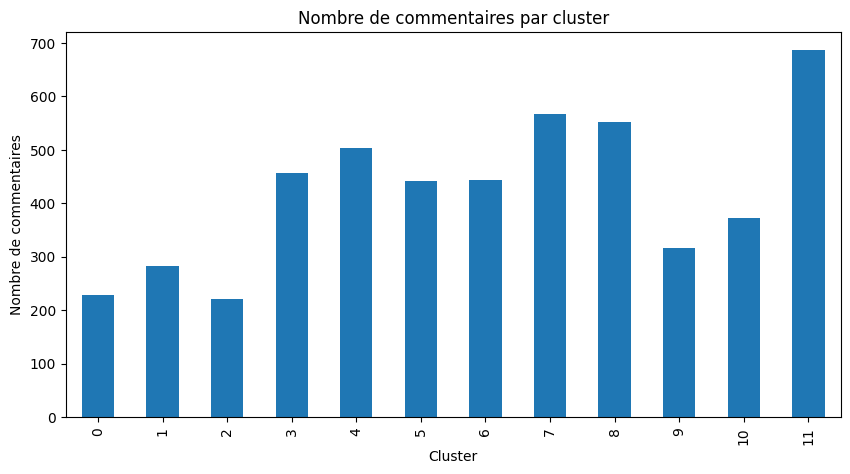

In [ ]:
cluster_sizes.plot(
    x="cluster",
    y="nombre_commentaires",
    kind="bar",
    legend=False,
    figsize=(10, 5))

plt.title("Nombre de commentaires par cluster")
plt.xlabel("Cluster")
plt.ylabel("Nombre de commentaires")
plt.show()

Démarche :

- on prend les centres des 12 clusters,
- on calcule la distance entre chaque commentaire et chaque centre,
- pour chaque commentaire, on garde seulement la distance avec le centre de son propre cluster,
- on trie les commentaires du plus proche au plus éloigné du centre,
- pour chaque cluster, on prend les k (5 ou 10) commentaires les plus proches,
- ces commentaires sont considérés comme les meilleurs exemples pour comprendre le cluster en question.

---

In [ ]:
df_repr = table_filtre.copy()
centroids = kmeans.cluster_centers_

distances = pairwise_distances(X, centroids, metric="euclidean")

df_repr["distance_to_centroid"] = [
    distances[i, cluster]
    for i, cluster in enumerate(df_repr["cluster_kmeans_llm"])]

representatifs = (df_repr.sort_values(["cluster_kmeans_llm", "distance_to_centroid"]).groupby("cluster_kmeans_llm").head(10)
[["cluster_kmeans_llm", "distance_to_centroid", "content", "agree_score", "disagree_score", "neutral_score"]])
representatifs

,cluster_kmeans_llm,distance_to_centroid,content,agree_score,disagree_score,neutral_score
632,0,0.580130,Il faut installer les datacenters avec des pan...,0.79,0.06,0.15
3945,0,0.583672,Il faut installer des panneaux solaire sur les...,0.73,0.10,0.17
3675,0,0.598067,Il faut que les data center puissent produire ...,0.73,0.09,0.18
2671,0,0.599318,Il faut récupérer l'énergie calorifique de l'e...,0.83,0.04,0.13
3693,0,0.607341,Il faut brancher les datas centers sur des pan...,0.63,0.12,0.25
...,...,...,...,...,...,...
2023,11,0.630653,Il faut inciter les fabricants à vendre des ap...,0.89,0.06,0.05
5049,11,0.632592,Il faut déprogrammer l'obsolescence des appare...,0.85,0.05,0.10
709,11,0.633121,Il faut promouvoir les équipements durables et...,0.86,0.05,0.09
1105,11,0.634710,Il faut que l’on se remette à fabriquer des éq...,0.93,0.02,0.05


**Interprétation:**

L’approche par Word Embedding et KMeans permet de faire émerger des groupes de réponses clients sémantiquement proches.

Au total, 12 clusters ressortent et peuvent être interprétés comme suit:

- Cluster 0: Data centers et énergie renouvelable
- Cluster 1: Réduction du streaming et de la consommation de data
- Cluster 2: Opposition à la 5G
- Cluster 3: Mutualisation des box et équipements réseau
- Cluster 4: Suppression de la publicité numérique
- Cluster 5: Sobriété numérique générale
- Cluster 6: Nettoyage des mails inutiles
- Cluster 7: Sensibilisation et mesure de l’impact carbone
- Cluster 8: Allongement de la durée de vie des smartphones
- Cluster 9: Mise en veille / extinction automatique des appareils
- Cluster 10: Fin des forfaits illimités
- Cluster 11: Réparation, recyclage et durabilité des appareils

Les clusters obtenus mettent en évidence plusieurs attentes récurrentes : une réduction de la consommation de données, notamment liée au streaming et aux forfaits illimités ; une remise en question de la 5G ; une meilleure gestion énergétique des infrastructures comme les data centers et les box ; ainsi qu’un allongement de la durée de vie des équipements grâce à la réparation, au recyclage et au reconditionnement.

Cette approche vient confirmer les résultats du topic modelling, tout en apportant une lecture plus fine des propositions concrètes formulées par les clients.



## Visualisation 2D avec UMAP

---

In [ ]:
df_viz = table_filtre.copy()

# on raccourcit le texte pour l'affichage
df_viz["content_short"] = (df_viz["content"]
    .fillna("")
    .str.replace("\n", " ", regex=False)
    .str.slice(0, 180))

# projection UMAP en 2D :
reducer = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric="cosine",
    random_state=42)

X_umap = reducer.fit_transform(X)

df_viz["umap_1"] = X_umap[:, 0]
df_viz["umap_2"] = X_umap[:, 1]

fig = px.scatter(
    df_viz,
    x="umap_1",
    y="umap_2",
    color=df_viz["cluster_kmeans_llm"].astype(str),
    hover_data={
        "content_short": True,
        "agree_score": True,
        "disagree_score": True,
        "neutral_score": True,
        "author.age": True,
        "umap_1": False,
        "umap_2": False
    },
    title="Visualisation des clusters K-Means sur embeddings Solon avec UMAP",
    labels={"color": "Cluster"})

fig.update_traces(marker=dict(size=7, opacity=0.75))
fig.show()

## Approche 3 - Word2Vec + Clustering

---

In [ ]:
df_w2v = table_filtre.copy()

df_w2v["tokens_w2v"] = df_w2v["content_tokens"].apply(lambda x: x if isinstance(x, list) else [])

df_w2v = df_w2v[df_w2v["tokens_w2v"].apply(len) > 0].reset_index(drop=True)

sentences = df_w2v["tokens_w2v"].tolist()

print("nb de contribs :", len(sentences))
print("ex de tokens :", sentences[0])

nb de contribs : 5069
ex de tokens : ['proposer', 'client', 'utiliser', 'smartphone', 'reduction', 'forfait']


In [ ]:
w2v_model = Word2Vec(
    sentences=sentences,
    vector_size=100,     # taille des vecteurs
    window=5,            # contexte de 5 mots autour du mot cible
    min_count=2,         # ignore les mots qui apparaissent une seule fois
    sg=0,                # 0 = CBOW ; 1 = Skip-Gram
    negative=10,
    sample=1e-3,
    epochs=80,
    workers=1,
    seed=42)

print("Taille du vocabulaire Word2Vec :", len(w2v_model.wv))

Taille du vocabulaire Word2Vec : 2557


In [ ]:
tfidf_vectorizer = TfidfVectorizer(
    tokenizer=lambda x: x,
    preprocessor=lambda x: x,
    token_pattern=None,
    lowercase=False,
    min_df=2,
    max_df=0.90)

X_tfidf = tfidf_vectorizer.fit_transform(df_w2v["tokens_w2v"])
vocab = tfidf_vectorizer.get_feature_names_out()

valid_idx = [i for i, word in enumerate(vocab) if word in w2v_model.wv]
valid_vocab = vocab[valid_idx]

X_tfidf_valid = X_tfidf[:, valid_idx]
word_vectors = np.vstack([w2v_model.wv[word] for word in valid_vocab])

X_w2v = X_tfidf_valid @ word_vectors

weights_sum = np.asarray(X_tfidf_valid.sum(axis=1)).ravel()
X_w2v = np.asarray(X_w2v) / np.maximum(weights_sum[:, None], 1e-12)

X_w2v = normalize(X_w2v)

print("Matrice finale des contributions :", X_w2v.shape)

Matrice finale des contributions : (5069, 100)


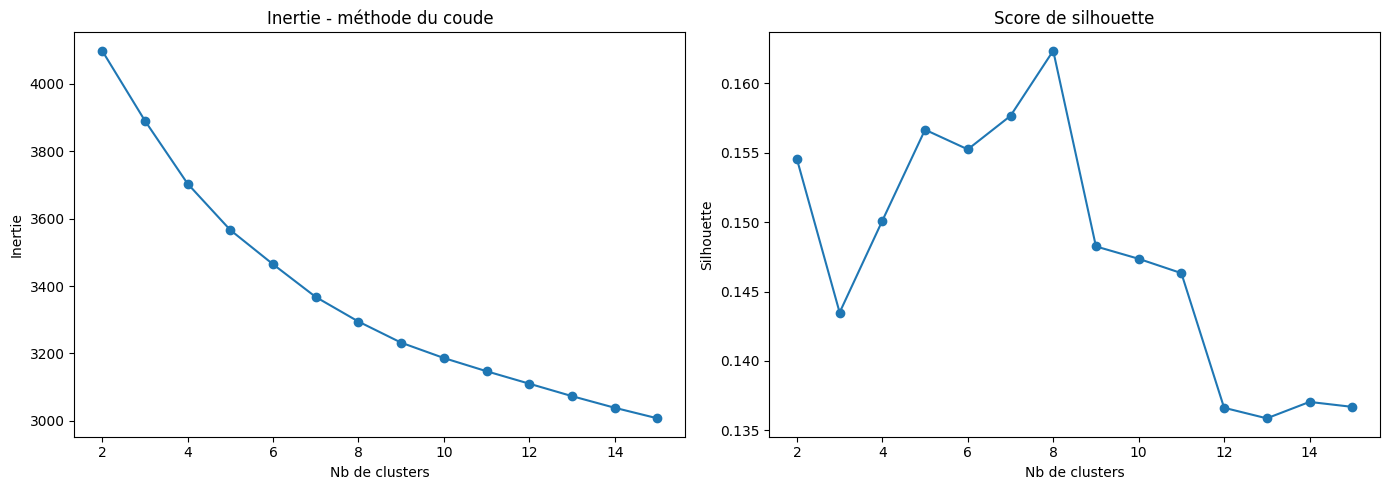

In [ ]:
inerties = []
silhouettes = []

K_range = range(2, 16)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=30)
    labels = km.fit_predict(X_w2v)

    inerties.append(km.inertia_)
    silhouettes.append(
        silhouette_score(
            X_w2v,
            labels,
            metric="cosine",
            sample_size=min(2000, X_w2v.shape[0]),
            random_state=42
        )
    )

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(K_range, inerties, marker="o")
ax1.set_title("Inertie - méthode du coude")
ax1.set_xlabel("Nb de clusters")
ax1.set_ylabel("Inertie")

ax2.plot(K_range, silhouettes, marker="o")
ax2.set_title("Score de silhouette")
ax2.set_xlabel("Nb de clusters")
ax2.set_ylabel("Silhouette")

plt.tight_layout()
plt.show()

In [77]:
k_optimal_w2v = 8

kmeans_w2v = KMeans(
    n_clusters=k_optimal_w2v,
    random_state=42,
    n_init=30)

df_w2v["cluster_kmeans_w2v"] = kmeans_w2v.fit_predict(X_w2v)

In [ ]:
cluster_sizes_w2v = (
    df_w2v["cluster_kmeans_w2v"]
    .value_counts()
    .sort_index()
    .reset_index())

cluster_sizes_w2v.columns = ["cluster", "nombre_contributions"]
cluster_sizes_w2v["part_%"] = (
    cluster_sizes_w2v["nombre_contributions"] / len(df_w2v) * 100).round(2)

cluster_sizes_w2v

,cluster,nombre_contributions,part_%
0,0,396,7.81
1,1,781,15.41
2,2,540,10.65
3,3,559,11.03
4,4,1190,23.48
5,5,619,12.21
6,6,423,8.34
7,7,561,11.07


In [ ]:
centroids_w2v = kmeans_w2v.cluster_centers_

distances = pairwise_distances(
    X_w2v,
    centroids_w2v,
    metric="cosine"
)

df_w2v["distance_to_centroid_w2v"] = [
    distances[i, cluster]
    for i, cluster in enumerate(df_w2v["cluster_kmeans_w2v"])
]

representatifs_w2v = (
    df_w2v
    .sort_values(["cluster_kmeans_w2v", "distance_to_centroid_w2v"])
    .groupby("cluster_kmeans_w2v")
    .head(10)
    [[
        "cluster_kmeans_w2v",
        "distance_to_centroid_w2v",
        "content",
        "agree_score",
        "disagree_score",
        "neutral_score"
    ]])

representatifs_w2v  #les 10 propositions les plus representatives de chaque cluster

,cluster_kmeans_w2v,distance_to_centroid_w2v,content,agree_score,disagree_score,neutral_score
2799,0,0.131555,Il faut construire les piscines municipales à proximité des datacenter et autres centraux Orange pour chauffer l'eau.,0.58,0.17,0.25
632,0,0.138679,Il faut installer les datacenters avec des panneaux solaires avec récupération de la chaleur pour des habitations/serres chauffées,0.79,0.06,0.15
4507,0,0.147839,"Il faut redistribuer la chaleur générée par les répartiteurs, centraux télécoms présents dans chaque commune (impliquer les collectivités)",0.80,0.04,0.16
2884,0,0.149774,Il faut construire les bureaux des opérateurs téléphoniques à côté de leurs propres data centers et utiliser la chaleur pour s'auto chauffer,0.64,0.12,0.24
1363,0,0.153797,Il faut récupérer l'énergie des serveurs Telecom afin d'être utiliser comme source de chaleur pour du chauffage ou autre.,0.83,0.04,0.13
3889,0,0.158083,Il faut récupérer la chaleur que dégage les infrastructures des opérateurs pour chauffer les bâtiments et alentours,0.86,0.05,0.09
2269,0,0.160901,"Il faut alimenter les bureaux en élec, clim, chauffage avec des panneaux photovoltaïques en autoconsommation (mon bâtiment > 2000m² de toit)",0.77,0.07,0.16
3327,0,0.161171,Il faut réutiliser la chaleur produite par les salles techniques pour chauffer les bureaux adjacents en hiver,0.86,0.03,0.11
3209,0,0.163463,Il faut utiliser la chaleur émise par les serveurs pour chauffer des bâtiments,0.81,0.05,0.14
1473,0,0.167238,"Il faut que l’ensemble des serveurs soient plus sobres, alimenté par des énergies renouvelables et que la chaleur produite soit valorisée.",0.85,0.04,0.11


In [ ]:
for cluster in sorted(df_w2v["cluster_kmeans_w2v"].unique()):
    idx = np.where(df_w2v["cluster_kmeans_w2v"].values == cluster)[0]

    mean_tfidf = np.asarray(X_tfidf_valid[idx].mean(axis=0)).ravel()
    top_idx = mean_tfidf.argsort()[-12:][::-1]

    top_words = valid_vocab[top_idx]

    print(f"\nCluster {cluster} - {len(idx)} contributions")
    print("Mots caractéristiques :", " | ".join(top_words))


Cluster 0 - 396 contributions
Mots caractéristiques : energie | solaire | chaleur | panneau | center | utiliser | data | datacenter | renouvelable | operateur | serveur | orange

Cluster 1 - 781 contributions
Mots caractéristiques : numerique | impact | usage | environnemental | numeriqu | carbone | consommation | sensibiliser | faire | informer | utilisation | utilisateur

Cluster 2 - 540 contributions
Mots caractéristiques : box | veille | eteindre | appareil | pouvoir | decodeur | nuit | heure | mettre | internet | wifi | couper

Cluster 3 - 559 contributions
Mots caractéristiques : video | streaming | limiter | reseau | social | publicite | reduire | donnee | qualite | contenu | interdire | internet

Cluster 4 - 1190 contributions
Mots caractéristiques : appareil | telephone | equipement | smartphone | obsolescence | proposer | produit | programme | reparation | recyclage | vie | batterie

Cluster 5 - 619 contributions
Mots caractéristiques : mail | supprimer | boite | spam | envo

**Description détaillée des clusters issus du Word2Vec + Clustering**

**Cluster 0: Valorisation énergétique des data centers**

Description: Regroupe des propositions autour de la réduction de l’impact énergétique des data centers et infrastructures télécoms. Les clients proposent notamment d’installer des panneaux solaires, de récupérer la chaleur produite par les serveurs et de la réutiliser pour chauffer des bâtiments, des bureaux ou des équipements publics.

---

**Cluster 1: Sensibilisation et information des utilisateurs**

Description: Ce cluster met en avant le besoin d’informer les citoyens et les utilisateurs sur l’impact environnemental du numérique. Les propositions évoquent des outils pédagogiques, des formations, des indicateurs, des labels ou encore des tableaux de bord permettant de rendre visible l’impact des usages numériques.

---
**Cluster 2: Extinction automatique des box et équipements connectés**

Description: Ce cluster concerne la réduction de la consommation énergétique des box internet, décodeurs et équipements domestiques. Les clients demandent des fonctionnalités permettant d’éteindre ou de mettre automatiquement en veille les équipements lorsqu’ils ne sont pas utilisés, notamment la nuit ou en cas d’absence.

---
**Cluster 3: Réduction du streaming et des flux vidéo**

Description: Ce cluster regroupe les propositions visant à limiter les usages très consommateurs de données, surtout le streaming vidéo. Les clients suggèrent de réduire la qualité des vidéos, de limiter la 4K/8K, de privilégier le téléchargement local ou encore de compresser davantage les flux pour réduire la consommation de bande passante.

---
**Cluster 4: Durabilité, réparation et recyclage des équipements**

Description: Ce cluster porte sur l’allongement de la durée de vie des appareils numériques. Les propositions insistent sur la réparation, le reconditionnement, le recyclage, l’uniformisation des chargeurs, la lutte contre l’obsolescence programmée et l’obligation pour les fabricants de concevoir des équipements plus durables.

---
**Cluster 5: Nettoyage des mails et réduction du stockage inutile**

Description: Ce cluster rassemble les propositions autour de la gestion des e-mails. Les clients souhaitent supprimer régulièrement les mails inutiles, vider les corbeilles, se désabonner des newsletters, limiter les spams et réduire le stockage inutile de données dans les messageries.

---
**Cluster 6: Remise en question de la 5G et priorité à la 4G**

Description: Ce cluster exprime une critique du déploiement de la 5G, jugée peu utile, énergivore ou prématurée. Les clients proposent plutôt de renforcer la couverture 4G, notamment dans les zones rurales ou mal couvertes, avant de développer de nouvelles générations de réseaux.

---
**Cluster 7: Forfaits sobres et tarification selon la consommation réelle**

Description: Ce cluster concerne les offres mobiles et internet. Les clients souhaitent sortir de la logique des forfaits illimités, proposer des forfaits personnalisés, moins riches en data, avec des plafonds ou une tarification progressive selon la consommation réelle afin d’encourager la sobriété.



In [ ]:
import textwrap

In [ ]:
df_votes = table_filtre.copy()

colonnes_votes = [
    "agree_count",
    "disagree_count",
    "neutral_count"
]

colonnes_necessaires = ["content"] + colonnes_votes

colonnes_manquantes = [
    col for col in colonnes_necessaires
    if col not in df_votes.columns
]

if len(colonnes_manquantes) > 0:
    raise ValueError(f"Colonnes manquantes : {colonnes_manquantes}")

In [ ]:
for col in colonnes_votes:
    df_votes[col] = pd.to_numeric(df_votes[col], errors="coerce").fillna(0)

df_votes["content"] = df_votes["content"].fillna("").astype(str)

df_votes["total_votes"] = (
    df_votes["agree_count"]
    + df_votes["disagree_count"]
    + df_votes["neutral_count"]
)

df_votes["votes_engages"] = (
    df_votes["agree_count"]
    + df_votes["disagree_count"]
)

df_votes["pct_pour_total"] = np.where(
    df_votes["total_votes"] > 0,
    df_votes["agree_count"] / df_votes["total_votes"],
    0
)

df_votes["pct_contre_total"] = np.where(
    df_votes["total_votes"] > 0,
    df_votes["disagree_count"] / df_votes["total_votes"],
    0
)

df_votes["pct_neutre_total"] = np.where(
    df_votes["total_votes"] > 0,
    df_votes["neutral_count"] / df_votes["total_votes"],
    0
)

df_votes["pct_pour_engage"] = np.where(
    df_votes["votes_engages"] > 0,
    df_votes["agree_count"] / df_votes["votes_engages"],
    0
)

df_votes["pct_contre_engage"] = np.where(
    df_votes["votes_engages"] > 0,
    df_votes["disagree_count"] / df_votes["votes_engages"],
    0
)

In [ ]:
top5_propositions = (
    df_votes
    .sort_values(["pct_pour_total", "agree_count"], ascending=False)
    .head(5)
    .reset_index(drop=True)
)

top5_propositions["rang"] = top5_propositions.index + 1

top5_propositions["content_court"] = top5_propositions["content"].apply(
    lambda x: textwrap.shorten(x, width=110, placeholder="...")
)

display(
    top5_propositions[
        [
            "rang",
            "content_court",
            "agree_count",
            "disagree_count",
            "neutral_count",
            "total_votes",
            "pct_pour_total",
            "pct_contre_total"
        ]
    ]
)

,rang,content_court,agree_count,disagree_count,neutral_count,total_votes,pct_pour_total,pct_contre_total
0,1,Il faut augmenter la durée de garantie et la r...,772,8,15,795,0.971069,0.010063
1,2,Il faut inciter les constructeurs à augmenter ...,697,8,16,721,0.966713,0.011096
2,3,Il faut une durabilité des appareils et des ch...,688,11,14,713,0.964937,0.015428
3,4,Il faut que les téléphones puissent se réparer...,790,11,20,821,0.962241,0.013398
4,5,Il faut que les appareils durent plus longtemp...,633,10,16,659,0.960546,0.015175


In [ ]:
for i, texte in enumerate(top5_propositions.sort_values(by="rang")["content"], start=1):
    print(f"\n#{i}")
    print(texte)


#1
Il faut augmenter la durée de garantie et la réparabilité des équipements, par exemple, pouvoir changer simplement de batterie

#2
Il faut inciter les constructeurs à augmenter la durée de vie des équipements (réparabilité, mise à jour logiciel).

#3
Il faut une durabilité des appareils et des chargeurs universels pour éviter la pollution et l'augmentation des déchets, produire mieux.

#4
Il faut que les téléphones puissent se réparer facilement, à un coût bien inférieur par rapport à du matériel neuf

#5
Il faut que les appareils durent plus longtemps dans le temps. Qu'ils puissent être réparés plus facilement pour les garder plus longtemps


In [ ]:
top5_propositions = (
    df_votes
    .sort_values(["agree_count", "total_votes"], ascending=False)
    .head(5)
    .reset_index(drop=True)
)

top5_propositions["rang"] = top5_propositions.index + 1

top5_propositions["content_court"] = top5_propositions["content"].apply(
    lambda x: textwrap.shorten(x, width=110, placeholder="...")
)

display(
    top5_propositions[
        [
            "rang",
            "content_court",
            "agree_count",
            "disagree_count",
            "neutral_count",
            "total_votes"
        ]
    ]
)

,rang,content_court,agree_count,disagree_count,neutral_count,total_votes
0,1,Il faut permettre à tous de réparer ses équipe...,8526,404,297,9227
1,2,Il faut que l'achat de téléphones reconditionn...,5883,319,312,6514
2,3,Il faut mettre en place des notifications prop...,2544,629,263,3436
3,4,Il faut taxer les milliards de mails publicita...,1590,69,66,1725
4,5,Il faut sensibiliser aux usages qui sont les p...,1177,226,165,1568


In [ ]:
top5_propositions["label"] = top5_propositions.apply(
    lambda row: f"#{int(row['rang'])} - " + textwrap.shorten(
        row["content"],
        width=70,
        placeholder="..."
    ),
    axis=1
)

couleurs_votes = {
    "agree_count": "#27ae60",
    "neutral_count": "#95a5a6",
    "disagree_count": "#e74c3c"
}

noms_votes = {
    "agree_count": "Pour",
    "neutral_count": "Neutres",
    "disagree_count": "Contre"
}

fig_top = go.Figure()

for col in ["agree_count", "neutral_count", "disagree_count"]:
    fig_top.add_trace(
        go.Bar(
            y=top5_propositions["label"],
            x=top5_propositions[col],
            name=noms_votes[col],
            orientation="h",
            marker_color=couleurs_votes[col],
            text=top5_propositions[col].astype(int),
            textposition="inside",
            hovertext=top5_propositions["content"],
            hovertemplate="%{hovertext}<br>Votes : %{x}<extra></extra>"
        )
    )

fig_top.update_layout(
    title="Top 5 propositions les plus plébiscitées",
    xaxis_title="Nombre de votes",
    yaxis_title="",
    barmode="stack",
    yaxis=dict(autorange="reversed"),
    template="plotly_white",
    height=450,
    margin=dict(l=430, r=40, t=80, b=50),
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="right",
        x=1
    )
)

fig_top.show()

In [ ]:
for i, texte in enumerate(top5_propositions.sort_values(by="rang", ascending=False)["content"], start=1):
    print(f"\n#{i}")
    print(texte)


#1
Il faut sensibiliser aux usages qui sont les plus générateurs de CO2 (renouvellement mobile, streaming vidéo HD sur mobile, etc.)

#2
Il faut taxer les milliards de mails publicitaires et les spams imbéciles qui transitent par les data-center, gros consommateurs d'énergie.

#3
Il faut mettre en place des notifications proposant des astuces pour réduire notre consommation d’énergie liée à nos usages d’internet.

#4
Il faut que l'achat de téléphones reconditionnés soit plus intéressant (prix, facilités de paiement, garanties) que ceux de téléphones neufs

#5
Il faut permettre à tous de réparer ses équipements dans les points de vente avec l'aide d'un spécialiste


In [ ]:
SEUIL_MIN_TOTAL_VOTES = 10
SEUIL_MIN_VOTES_ENGAGES = 5

df_controverse = df_votes[
    (df_votes["total_votes"] >= SEUIL_MIN_TOTAL_VOTES)
    & (df_votes["votes_engages"] >= SEUIL_MIN_VOTES_ENGAGES)
].copy()

df_controverse["equilibre_pour_contre"] = (
    1 - abs(df_controverse["pct_pour_engage"] - df_controverse["pct_contre_engage"])
)

df_controverse["score_controverse"] = (
    df_controverse["equilibre_pour_contre"]
    * np.log1p(df_controverse["votes_engages"])
)

top5_controverse = (
    df_controverse
    .sort_values(["score_controverse", "votes_engages"], ascending=False)
    .head(5)
    .reset_index(drop=True)
)

top5_controverse["rang"] = top5_controverse.index + 1

top5_controverse["content_court"] = top5_controverse["content"].apply(
    lambda x: textwrap.shorten(x, width=110, placeholder="...")
)

display(
    top5_controverse[
        [
            "rang",
            "content_court",
            "agree_count",
            "disagree_count",
            "neutral_count",
            "total_votes",
            "votes_engages",
            "pct_pour_engage",
            "pct_contre_engage",
            "score_controverse"
        ]
    ]
)

,rang,content_court,agree_count,disagree_count,neutral_count,total_votes,votes_engages,pct_pour_engage,pct_contre_engage,score_controverse
0,1,"Il faut proposer des forfaits dédiés à tiktok,...",319,311,125,755,630,0.506349,0.493651,6.365435
1,2,Il faut instaurer une taxe sur le volume de do...,280,279,134,693,559,0.500894,0.499106,6.316617
2,3,Il faut supprimer la gratuité des frais de por...,277,278,143,698,555,0.499099,0.500901,6.309380
3,4,Il faut mettre fin aux forfaits de données ill...,288,295,116,699,583,0.493997,0.506003,6.293418
4,5,Il faut arrêter avec les forfaits illimités po...,269,269,124,662,538,0.500000,0.500000,6.289716


In [ ]:
for i, texte in enumerate(top5_controverse.sort_values(by="rang", ascending=True)["content"], start=1):
    print(f"\n#{i}")
    print(texte)


#1
Il faut proposer des forfaits dédiés à tiktok, facebook, twitter, netflix et proposer des forfaits moins chers en dehors de ces usages

#2
Il faut instaurer une taxe sur le volume de données qui transite sur les réseaux pour inciter les usages plus raisonnables

#3
Il faut supprimer la gratuité des frais de port pour les sites de e-commerce, afin de réduire l'impact du transport des marchandises acquise

#4
Il faut mettre fin aux forfaits de données illimités et faire payer le consommateur en fonction de ce qu'il consomme.

#5
Il faut arrêter avec les forfaits illimités pour tout afin que les gens retournent à une consommation raisonnée de datas
